# Confidence Intervals and Bootstrap

Quantify uncertainty in sample estimates without overstating certainty.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Learning goals
- Interpret a confidence interval carefully.
- Calculate a standard-error-based interval for a mean under suitable assumptions.
- Build a bootstrap interval by resampling observed rows with replacement.
- Distinguish uncertainty about an estimate from variability among individual observations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rng = np.random.default_rng(202)
sample = rng.normal(loc=42, scale=10, size=45)
n = len(sample)
mean = sample.mean()
se = stats.sem(sample)
ci = stats.t.interval(confidence=0.95, df=n-1, loc=mean, scale=se)
print({"n": n, "mean": round(mean, 2), "95% t interval": tuple(round(v, 2) for v in ci)})

{'n': 45, 'mean': np.float64(43.25), '95% t interval': (np.float64(40.16), np.float64(46.33))}


## Interpreting confidence intervals
A frequentist 95% confidence procedure produces intervals that cover the fixed parameter in about 95% of repeated samples when its assumptions hold. It does not mean there is a 95% probability that this particular fixed parameter lies in the already calculated interval.

Bootstrap mean: 43.24
Percentile bootstrap interval: (np.float64(40.31), np.float64(46.21))


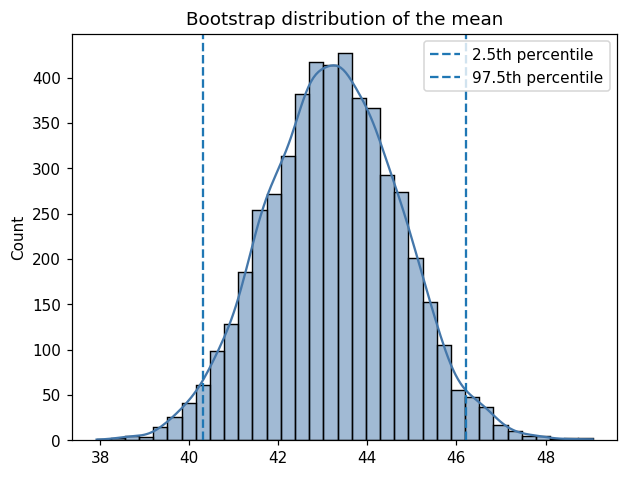

In [2]:
bootstrap_means = np.array([
    rng.choice(sample, size=len(sample), replace=True).mean()
    for _ in range(5000)
])
boot_ci = np.quantile(bootstrap_means, [0.025, 0.975])
print("Bootstrap mean:", round(bootstrap_means.mean(), 2))
print("Percentile bootstrap interval:", tuple(round(v, 2) for v in boot_ci))
sns.histplot(bootstrap_means, bins=35, kde=True, color="#4477AA")
plt.axvline(boot_ci[0], linestyle="--", label="2.5th percentile")
plt.axvline(boot_ci[1], linestyle="--", label="97.5th percentile")
plt.title("Bootstrap distribution of the mean")
plt.legend()
plt.show()

## Bootstrap for a median
Bootstrap is flexible, but it is not magic: it cannot recover important groups that never appear in the sample. If observations are paired, clustered, or time-dependent, resampling must respect that structure.

In [3]:
median_boot = np.array([
    np.median(rng.choice(sample, size=len(sample), replace=True))
    for _ in range(4000)
])
median_ci = np.quantile(median_boot, [0.025, 0.975])
print("Sample median:", round(np.median(sample), 2))
print("Median bootstrap interval:", tuple(round(v, 2) for v in median_ci))

Sample median: 43.95
Median bootstrap interval: (np.float64(37.98), np.float64(46.86))


## Practice
Calculate a bootstrap 95% interval for the median of a small sample. Fix a random seed so the example is reproducible.

In [4]:
rng = np.random.default_rng(7)
values = np.array([4, 5, 5, 6, 7, 8, 20])
boot = [np.median(rng.choice(values, len(values), replace=True)) for _ in range(3000)]
print("Median:", np.median(values))
print("95% bootstrap interval:", np.quantile(boot, [0.025, 0.975]))

Median: 6.0
95% bootstrap interval: [5. 8.]
